In [4]:
# ==============================================
# 1. 导入依赖库
# ==============================================
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from matplotlib.patches import FancyArrowPatch
import matplotlib.patches as patches

# 设置中文显示和图片尺寸
plt.rcParams["font.family"] = ["SimHei", "WenQuanYi Micro Hei", "Heiti TC"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.dpi'] = 300

# 创建保存图片的文件夹
import os
if not os.path.exists('figures'):
    os.makedirs('figures')

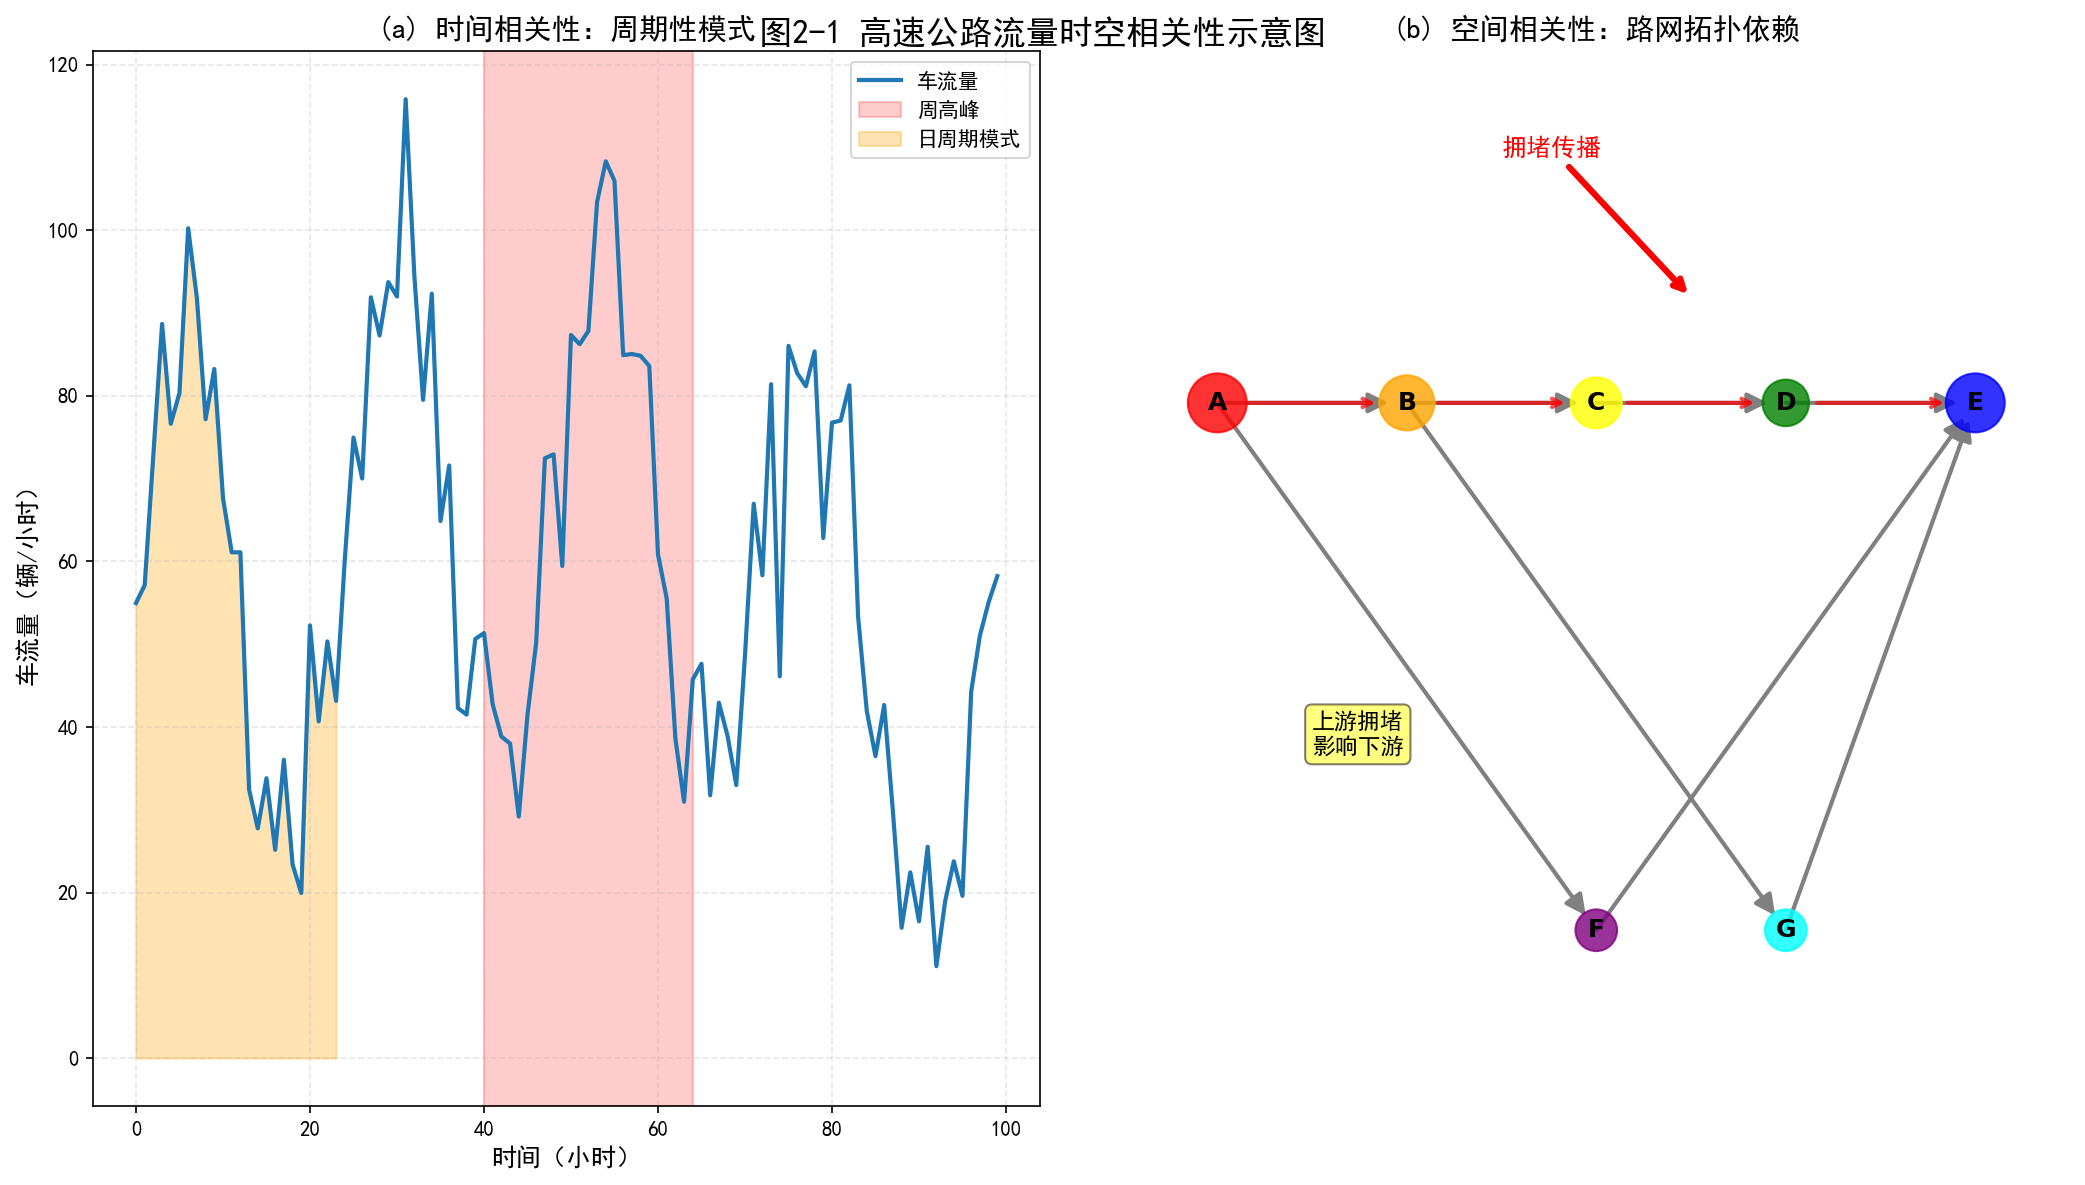

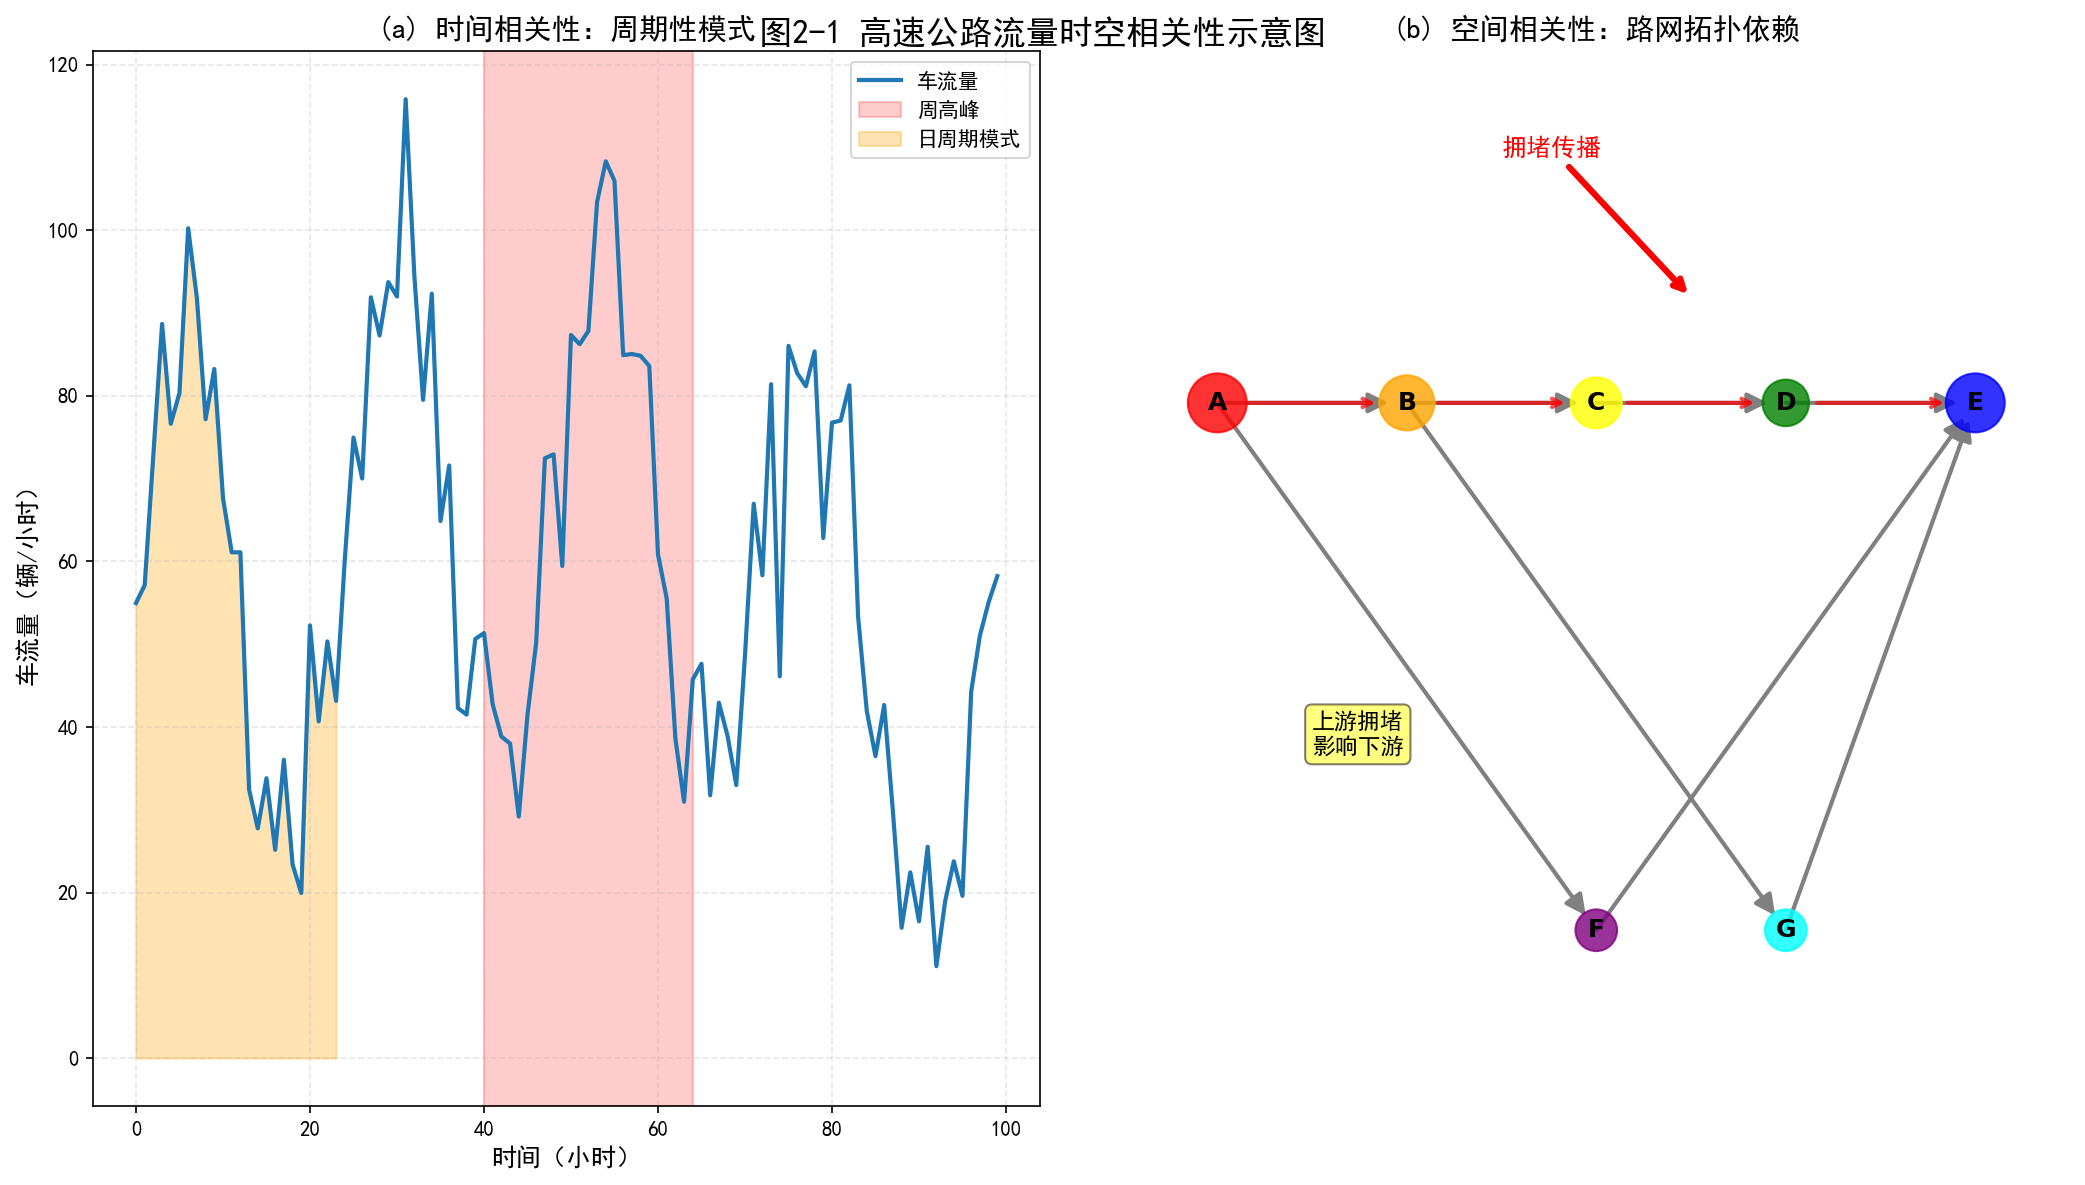

In [5]:
# ==============================================
# 图2-1：高速公路流量时空相关性示意图
# ==============================================
def create_spatiotemporal_correlation_figure():
    """
    创建高速公路流量的时空相关性示意图
    """
    fig = plt.figure(figsize=(14, 8))
    
    # 左侧：时间相关性示意图
    ax1 = plt.subplot(1, 2, 1)
    
    # 生成模拟的时间序列数据
    np.random.seed(42)
    time_points = np.arange(0, 100, 1)
    daily_pattern = 50 + 30 * np.sin(2 * np.pi * time_points / 24)  # 日周期
    weekly_pattern = 20 * np.sin(2 * np.pi * time_points / 168)     # 周周期
    noise = np.random.normal(0, 10, len(time_points))              # 随机噪声
    
    traffic_flow = daily_pattern + weekly_pattern + noise
    
    # 绘制时间序列
    ax1.plot(time_points, traffic_flow, linewidth=2, color='#1f77b4', label='车流量')
    
    # 标记日周期
    ax1.fill_between(time_points[:24], traffic_flow[:24], 0, alpha=0.3, color='orange', label='日周期模式')
    
    # 标记周高峰
    ax1.axvspan(40, 64, alpha=0.2, color='red', label='周高峰')
    
    ax1.set_xlabel('时间（小时）', fontsize=12)
    ax1.set_ylabel('车流量（辆/小时）', fontsize=12)
    ax1.set_title('(a) 时间相关性：周期性模式', fontsize=14, fontweight='bold')
    ax1.grid(alpha=0.3, linestyle='--')
    ax1.legend(loc='upper right')
    
    # 右侧：空间相关性示意图
    ax2 = plt.subplot(1, 2, 2)
    
    # 创建路网拓扑结构
    G = nx.DiGraph()
    
    # 添加节点（路段）
    nodes = ['A', 'B', 'C', 'D', 'E', 'F', 'G']
    G.add_nodes_from(nodes)
    
    # 添加边（连接关系）
    edges = [('A', 'B'), ('B', 'C'), ('C', 'D'), ('D', 'E'), 
             ('A', 'F'), ('F', 'E'), ('B', 'G'), ('G', 'E')]
    G.add_edges_from(edges)
    
    # 定义节点位置
    pos = {
        'A': (0, 1.5), 'B': (1, 1.5), 'C': (2, 1.5), 'D': (3, 1.5), 'E': (4, 1.5),
        'F': (2, 0), 'G': (3, 0)
    }
    
    # 绘制路网
    node_colors = ['red', 'orange', 'yellow', 'green', 'blue', 'purple', 'cyan']
    node_sizes = [800, 700, 600, 500, 800, 400, 400]
    
    nx.draw_networkx_nodes(G, pos, node_color=node_colors, 
                          node_size=node_sizes, alpha=0.8, ax=ax2)
    nx.draw_networkx_edges(G, pos, edge_color='gray', 
                          width=2, arrows=True, arrowsize=20, ax=ax2)
    nx.draw_networkx_labels(G, pos, font_size=12, font_weight='bold', ax=ax2)
    
    # 添加流量传播箭头
    for i, (u, v) in enumerate([('A', 'B'), ('B', 'C'), ('C', 'D'), ('D', 'E')]):
        ax2.annotate("", xy=pos[v], xytext=pos[u],
                    arrowprops=dict(arrowstyle="->", color='red', 
                                  lw=2, alpha=0.7, shrinkA=15, shrinkB=15))
    
    # 添加拥堵传播示意
    ax2.annotate("拥堵传播", xy=(2.5, 1.8), xytext=(1.5, 2.2),
                arrowprops=dict(arrowstyle="->", color='red', lw=3),
                fontsize=12, fontweight='bold', color='red')
    
    # 添加空间相关性说明
    ax2.text(0.5, 0.5, '上游拥堵\n影响下游', fontsize=11, 
             bbox=dict(boxstyle="round,pad=0.3", facecolor='yellow', alpha=0.5))
    
    ax2.set_xlim(-0.5, 4.5)
    ax2.set_ylim(-0.5, 2.5)
    ax2.set_title('(b) 空间相关性：路网拓扑依赖', fontsize=14, fontweight='bold')
    ax2.axis('off')
    
    # 添加主标题
    plt.suptitle('图2-1 高速公路流量时空相关性示意图', fontsize=16, fontweight='bold', y=0.98)
    plt.tight_layout()
    
    # 保存图片
    plt.savefig('figures/figure_2_1_spatiotemporal_correlation.png', 
                dpi=300, bbox_inches='tight', facecolor='white')
    plt.show()
    
    return fig

# 生成图2-1
create_spatiotemporal_correlation_figure()

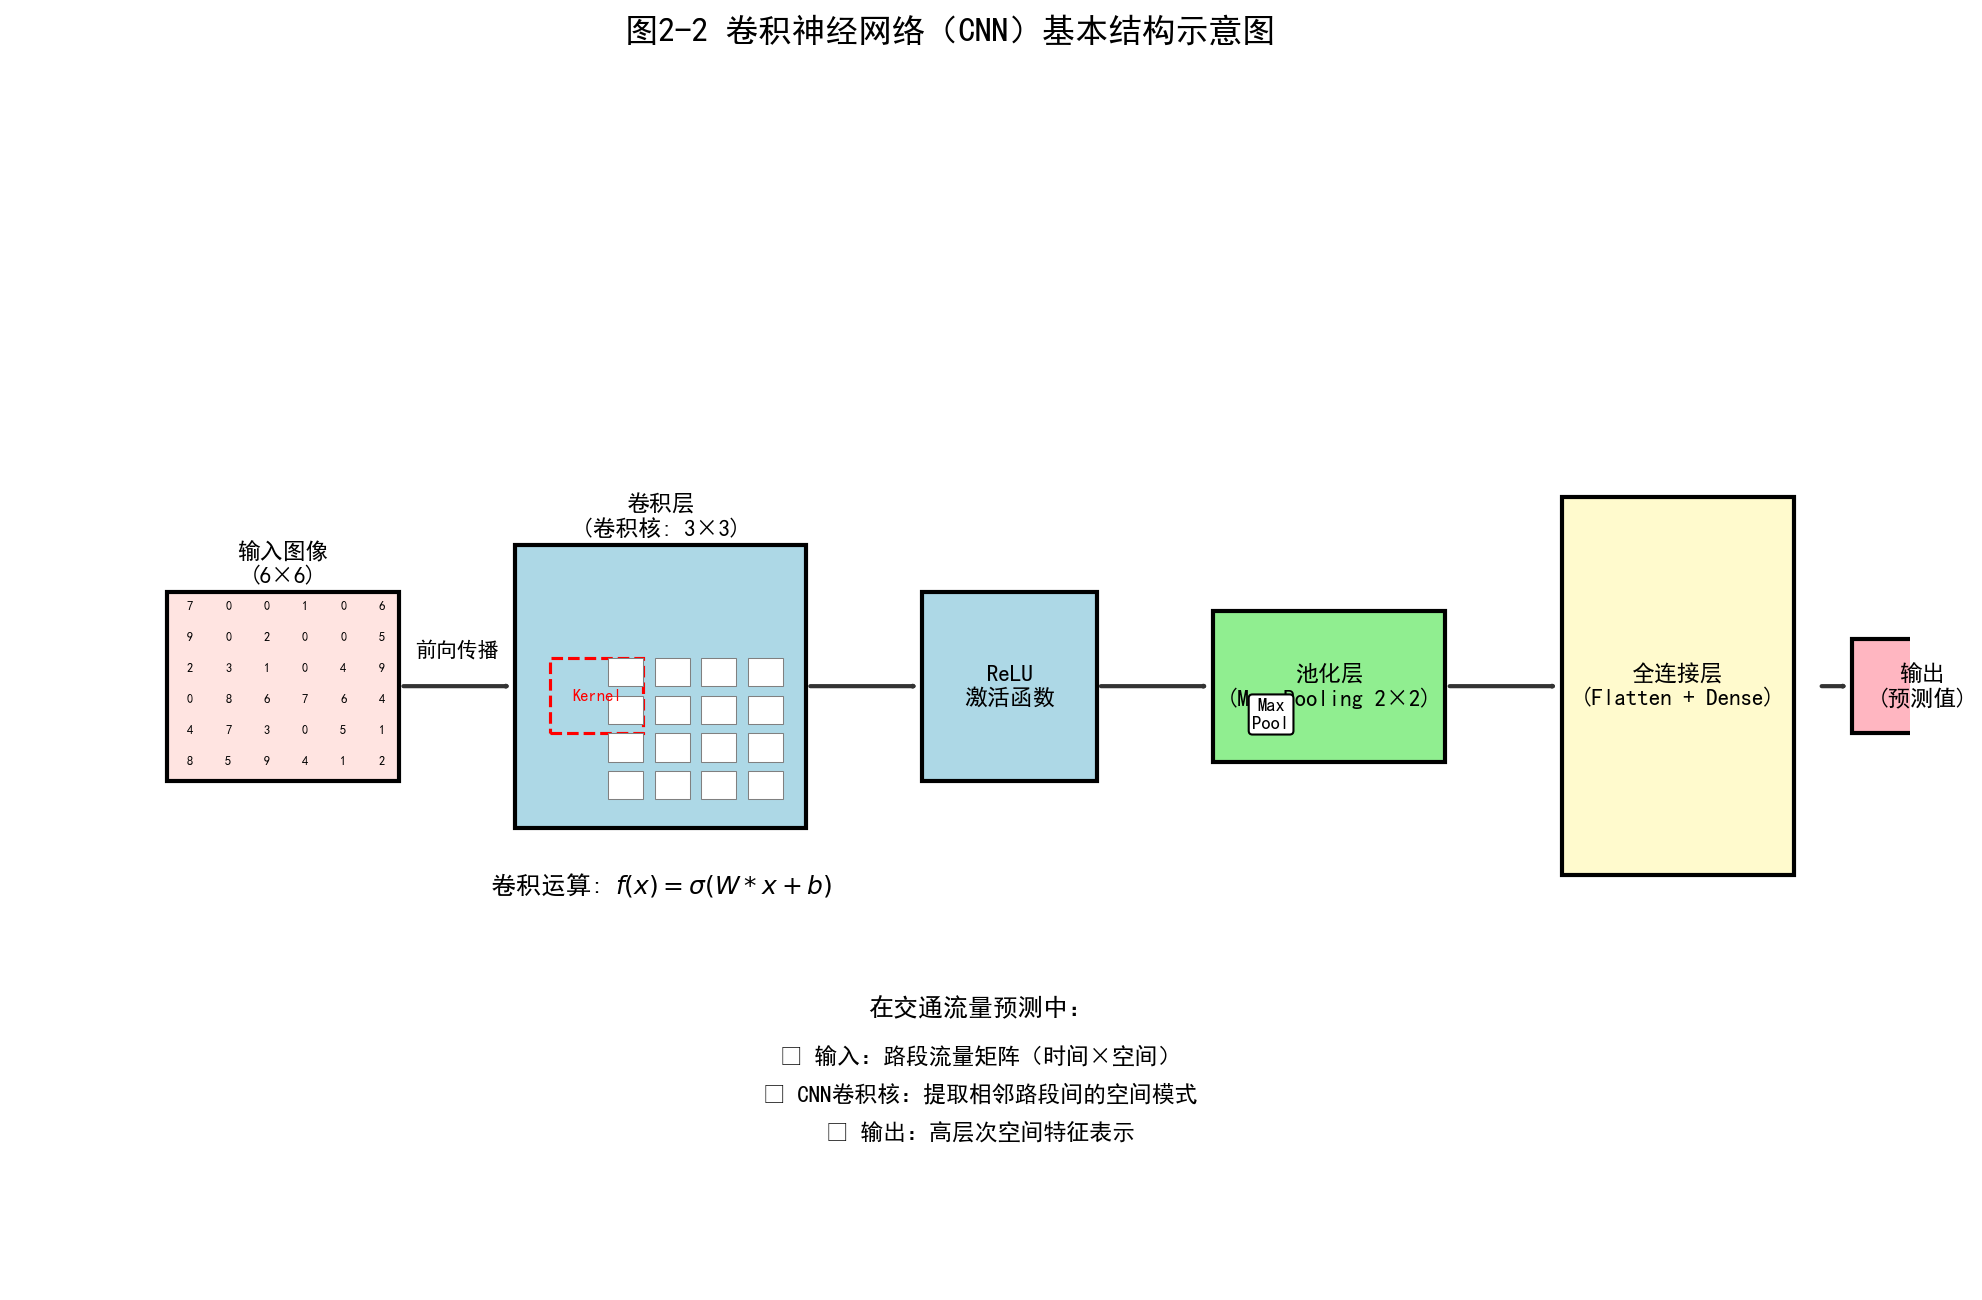

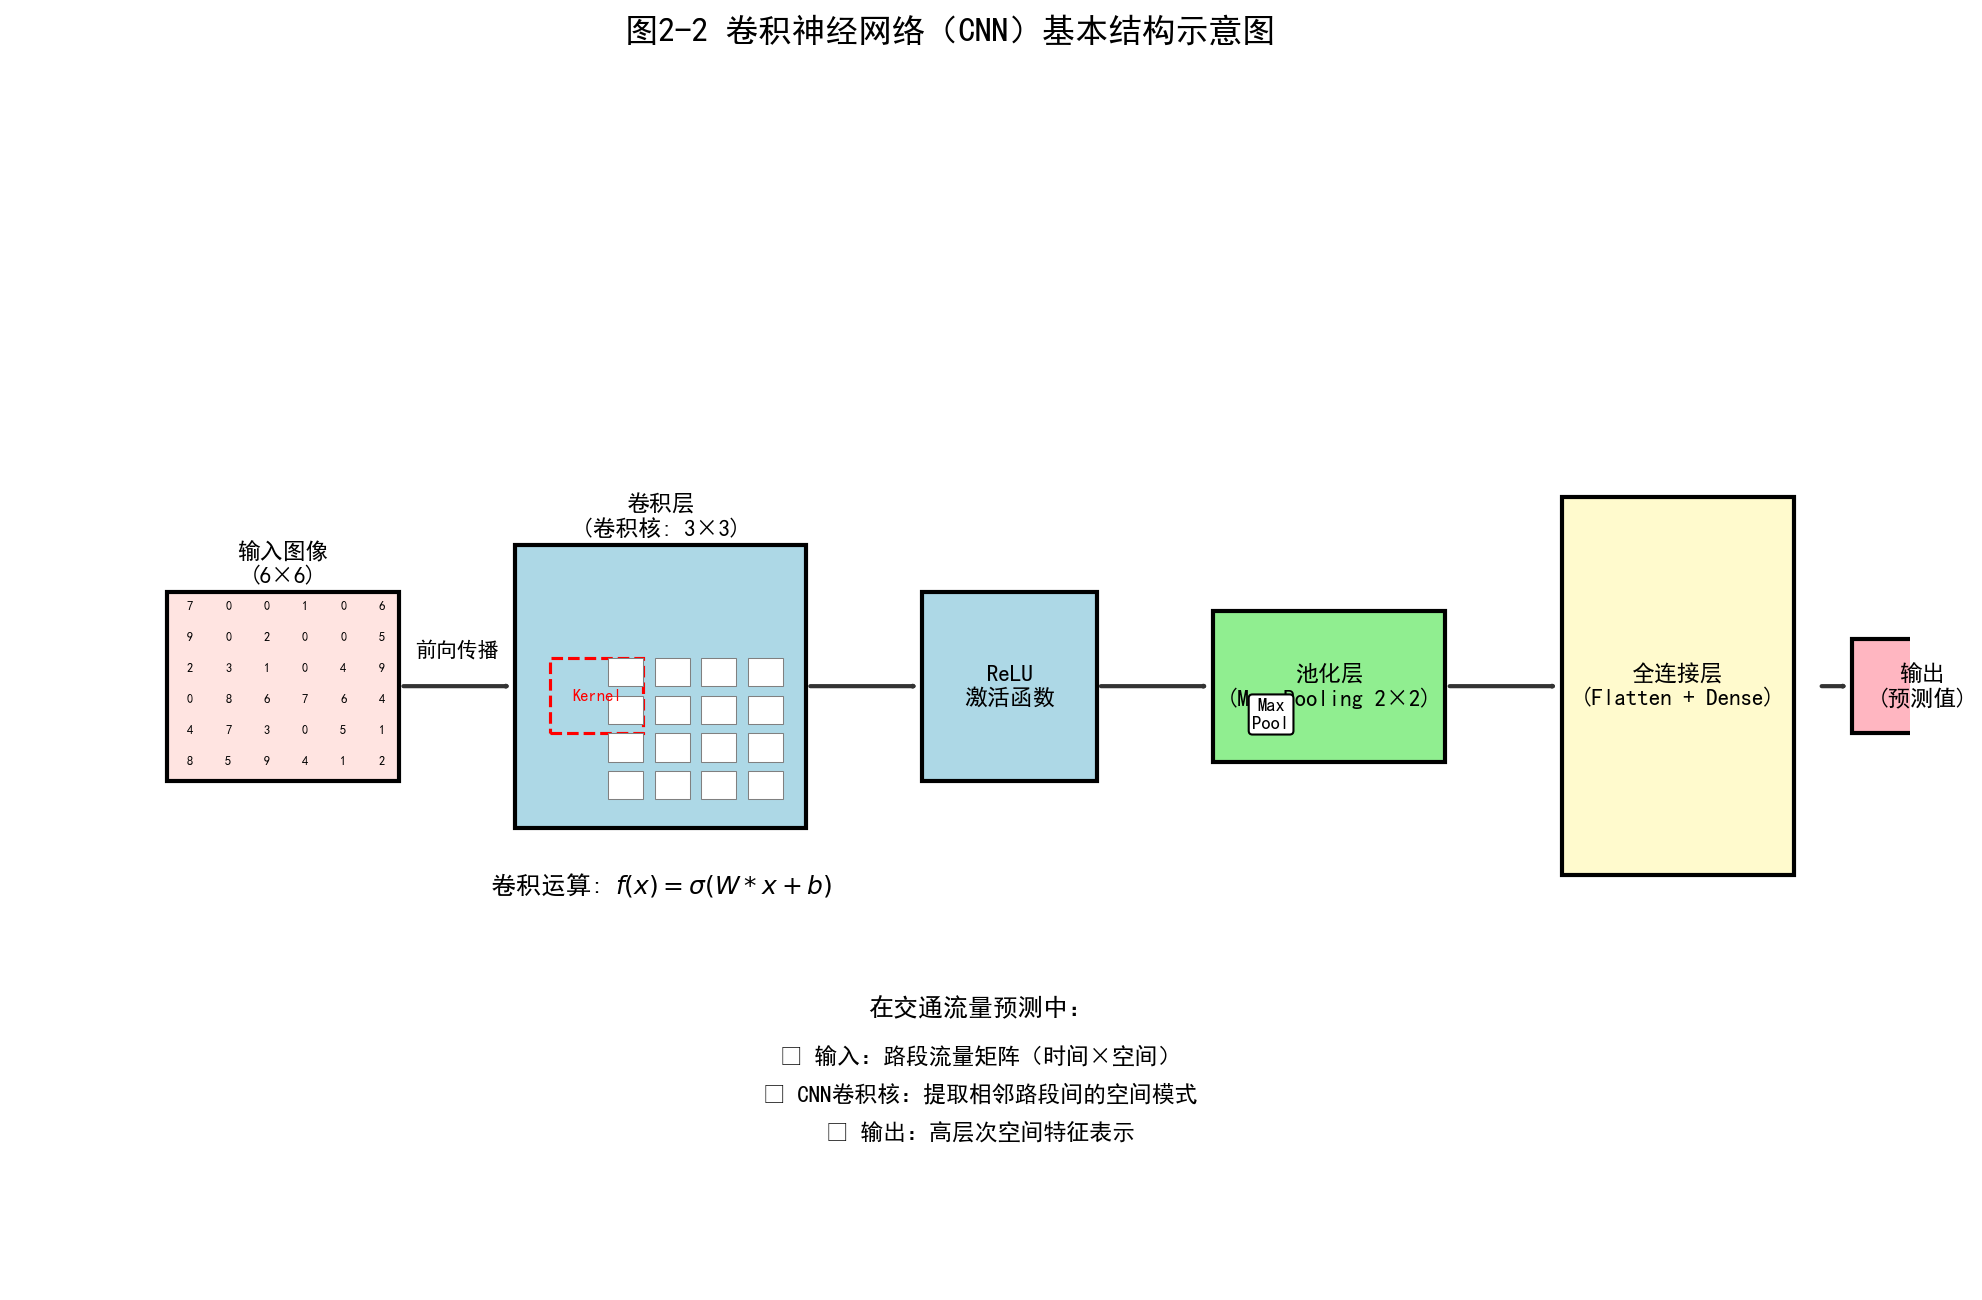

In [6]:
# ==============================================
# 图2-2：卷积神经网络基本结构示意图
# ==============================================
def create_cnn_architecture_figure():
    """
    创建CNN基本结构示意图
    """
    fig, ax = plt.subplots(figsize=(16, 10))
    ax.set_xlim(0, 16)
    ax.set_ylim(0, 12)
    ax.axis('off')
    
    # 颜色定义
    colors = {
        'input': '#FFE4E1',        # 输入层 - 淡粉色
        'conv': '#ADD8E6',         # 卷积层 - 淡蓝色
        'pool': '#90EE90',         # 池化层 - 淡绿色
        'fc': '#FFFACD',           # 全连接层 - 淡黄色
        'output': '#FFB6C1',       # 输出层 - 淡红色
        'arrow': '#333333'         # 箭头 - 深灰色
    }
    
    # 1. 输入层（图像）
    input_rect = patches.Rectangle((1, 5), 2, 2, linewidth=2, 
                                   edgecolor='black', facecolor=colors['input'])
    ax.add_patch(input_rect)
    ax.text(2, 7.3, '输入图像\n(6×6)', ha='center', va='center', 
            fontsize=11, fontweight='bold')
    
    # 输入图像中的像素示意
    for i in range(6):
        for j in range(6):
            x = 1.2 + i * 0.33
            y = 5.2 + j * 0.33
            value = np.random.randint(0, 10)
            ax.text(x, y, str(value), fontsize=6, ha='center', va='center')
    
    # 2. 卷积层
    conv_rect = patches.Rectangle((4, 4.5), 2.5, 3, linewidth=2, 
                                  edgecolor='black', facecolor=colors['conv'])
    ax.add_patch(conv_rect)
    ax.text(5.25, 7.8, '卷积层\n(卷积核: 3×3)', ha='center', va='center', 
            fontsize=11, fontweight='bold')
    
    # 卷积核示意
    kernel_x, kernel_y = 4.3, 5.5
    kernel_rect = patches.Rectangle((kernel_x, kernel_y), 0.8, 0.8, 
                                    linewidth=1.5, edgecolor='red', 
                                    facecolor='none', linestyle='--')
    ax.add_patch(kernel_rect)
    ax.text(kernel_x+0.4, kernel_y+0.4, 'Kernel', fontsize=8, 
            ha='center', va='center', color='red')
    
    # 特征图示意
    feature_x, feature_y = 4.8, 4.8
    for i in range(4):
        for j in range(4):
            rect = patches.Rectangle((feature_x + i*0.4, feature_y + j*0.4), 
                                     0.3, 0.3, facecolor='white', 
                                     edgecolor='gray', linewidth=0.5)
            ax.add_patch(rect)
    
    # 3. 激活层
    act_rect = patches.Rectangle((7.5, 5), 1.5, 2, linewidth=2, 
                                 edgecolor='black', facecolor=colors['conv'])
    ax.add_patch(act_rect)
    ax.text(8.25, 6, 'ReLU\n激活函数', ha='center', va='center', 
            fontsize=11, fontweight='bold')
    
    # 4. 池化层
    pool_rect = patches.Rectangle((10, 5.2), 2, 1.6, linewidth=2, 
                                  edgecolor='black', facecolor=colors['pool'])
    ax.add_patch(pool_rect)
    ax.text(11, 6, '池化层\n(Max Pooling 2×2)', ha='center', va='center', 
            fontsize=11, fontweight='bold')
    
    # 池化示意
    pool_x, pool_y = 10.3, 5.5
    ax.text(pool_x+0.2, pool_y+0.2, 'Max\nPool', fontsize=9, 
            ha='center', va='center', bbox=dict(boxstyle="round,pad=0.2", 
                                                facecolor='white'))
    
    # 5. 全连接层
    fc_rect = patches.Rectangle((13, 4), 2, 4, linewidth=2, 
                                edgecolor='black', facecolor=colors['fc'])
    ax.add_patch(fc_rect)
    ax.text(14, 6, '全连接层\n(Flatten + Dense)', ha='center', va='center', 
            fontsize=11, fontweight='bold')
    
    # 6. 输出层
    output_rect = patches.Rectangle((15.5, 5.5), 1.2, 1, linewidth=2, 
                                    edgecolor='black', facecolor=colors['output'])
    ax.add_patch(output_rect)
    ax.text(16.1, 6, '输出\n(预测值)', ha='center', va='center', 
            fontsize=11, fontweight='bold')
    
    # 添加连接箭头
    arrow_positions = [
        ((3, 6), (4, 6), '前向传播'),
        ((6.5, 6), (7.5, 6), ''),
        ((9, 6), (10, 6), ''),
        ((12, 6), (13, 6), ''),
        ((15.2, 6), (15.5, 6), '')
    ]
    
    for (x1, y1), (x2, y2), label in arrow_positions:
        arrow = FancyArrowPatch((x1, y1), (x2, y2), 
                                arrowstyle='->', lw=2, color=colors['arrow'])
        ax.add_patch(arrow)
        if label:
            ax.text((x1+x2)/2, y1+0.3, label, ha='center', fontsize=10)
    
    # 添加卷积运算公式
    ax.text(5.25, 3.8, '卷积运算: $f(x) = \\sigma(W * x + b)$', 
            ha='center', fontsize=12, fontweight='bold')
    
    # 添加CNN在交通预测中的应用说明
    ax.text(8, 2.5, '在交通流量预测中：', ha='center', fontsize=12, fontweight='bold')
    ax.text(8, 2.0, '• 输入：路段流量矩阵（时间×空间）', ha='center', fontsize=11)
    ax.text(8, 1.6, '• CNN卷积核：提取相邻路段间的空间模式', ha='center', fontsize=11)
    ax.text(8, 1.2, '• 输出：高层次空间特征表示', ha='center', fontsize=11)
    
    # 添加标题
    plt.suptitle('图2-2 卷积神经网络（CNN）基本结构示意图', 
                 fontsize=16, fontweight='bold', y=0.95)
    
    # 保存图片
    plt.savefig('figures/figure_2_2_cnn_architecture.png', 
                dpi=300, bbox_inches='tight', facecolor='white')
    plt.show()
    
    return fig

# 生成图2-2
create_cnn_architecture_figure()

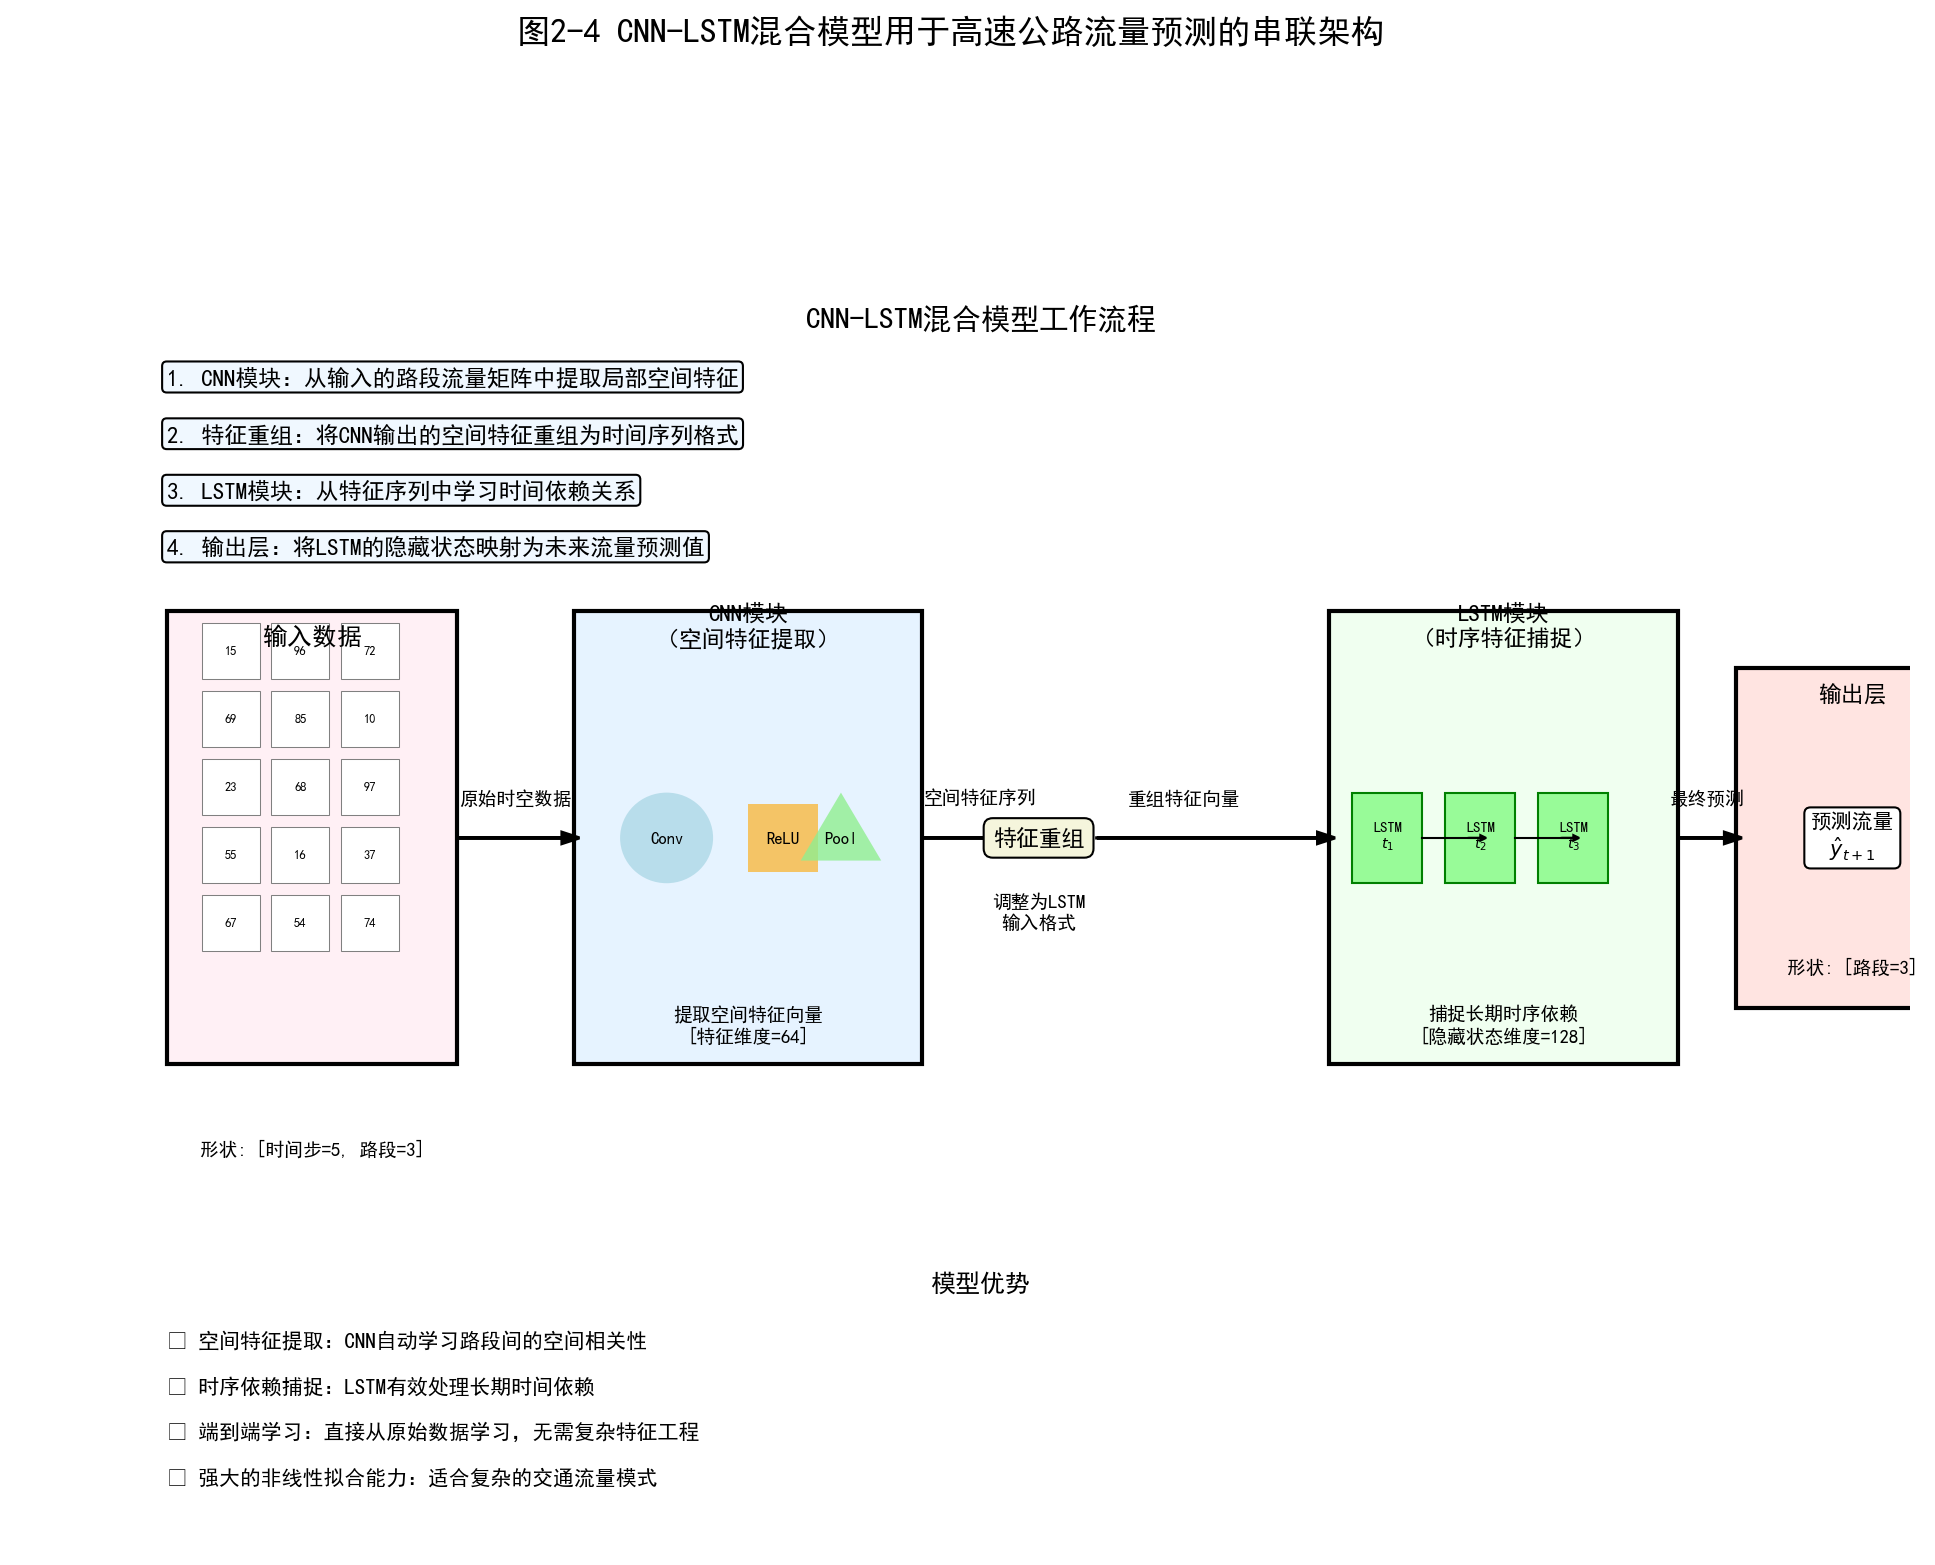

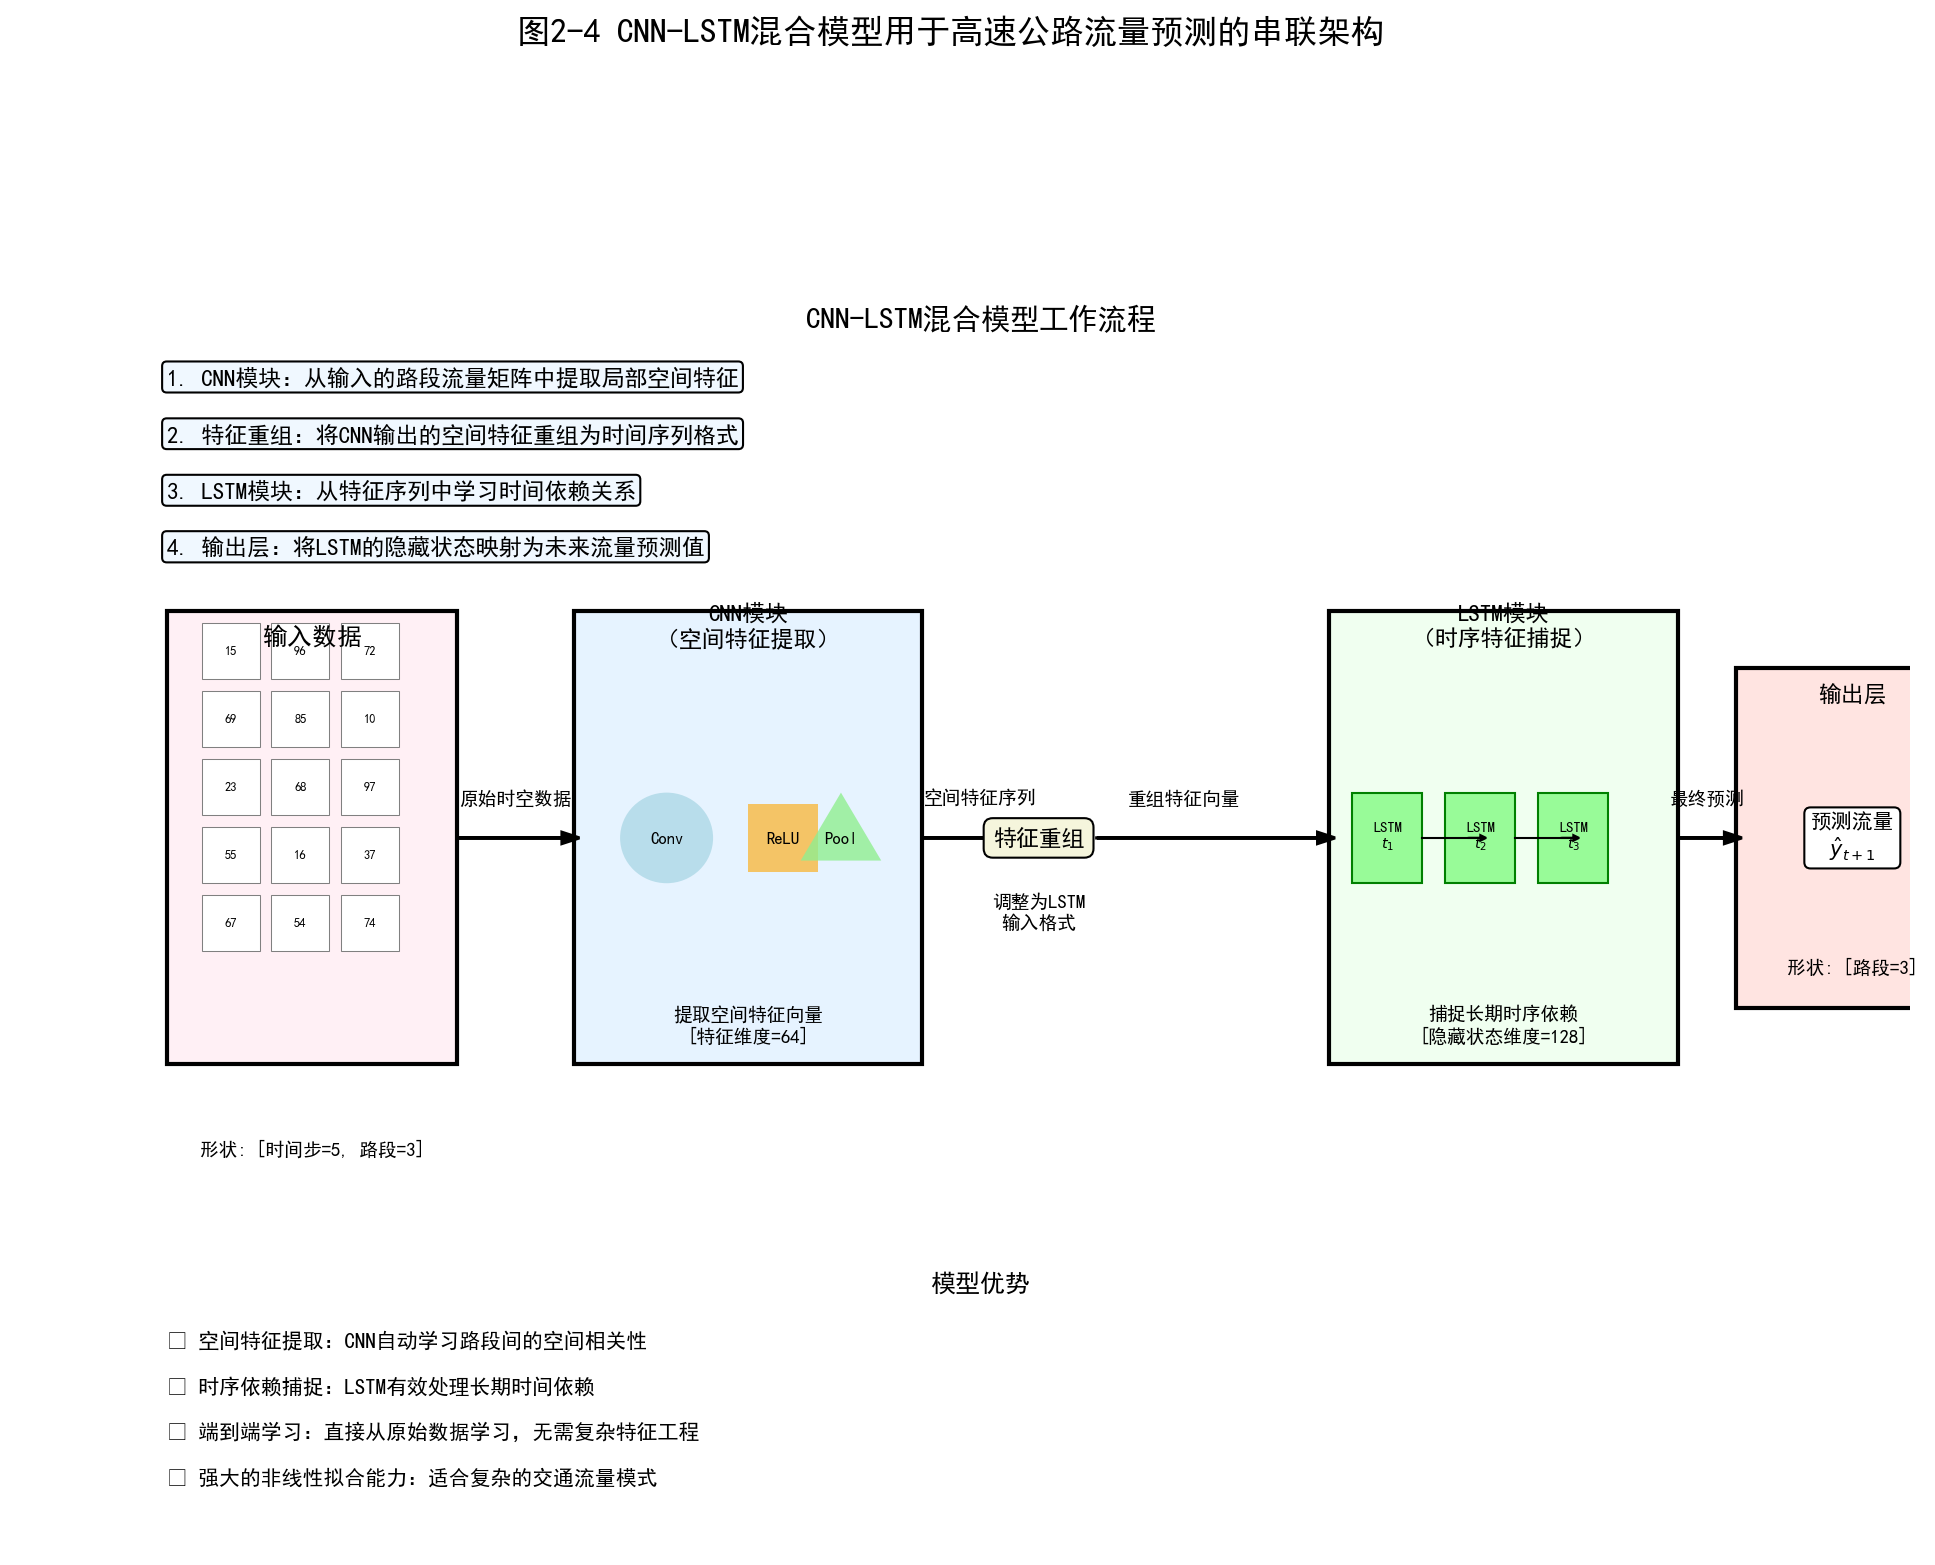

In [9]:
# ==============================================
# 图2-4：CNN-LSTM混合模型用于流量预测的串联架构图
# ==============================================
def create_cnn_lstm_architecture_figure():
    """
    创建CNN-LSTM混合模型架构图
    """
    fig = plt.figure(figsize=(16, 12))
    ax = plt.gca()
    ax.set_xlim(0, 16)
    ax.set_ylim(0, 12)
    ax.axis('off')
    
    # 模块颜色定义
    colors = {
        'input': '#FFF0F5',      # 输入 - 淡粉
        'cnn': '#E6F3FF',        # CNN模块 - 淡蓝
        'lstm': '#F0FFF0',       # LSTM模块 - 淡绿
        'fc': '#FFFACD',         # 全连接层 - 淡黄
        'output': '#FFE4E1',     # 输出 - 淡红
    }
    
    # ========== 1. 输入层 ==========
    input_x, input_y = 1, 6
    input_width, input_height = 2.5, 4
    
    # 输入数据框
    input_rect = patches.Rectangle((input_x, input_y - input_height/2), 
                                  input_width, input_height, 
                                  linewidth=2, edgecolor='black', 
                                  facecolor=colors['input'])
    ax.add_patch(input_rect)
    
    # 输入数据示意（路段×时间矩阵）
    ax.text(input_x + input_width/2, input_y + input_height/2 - 0.3, 
            '输入数据', fontsize=12, fontweight='bold', ha='center')
    
    # 矩阵示意
    matrix_x, matrix_y = input_x + 0.3, input_y - 1
    for i in range(5):  # 时间步
        for j in range(3):  # 路段
            rect = patches.Rectangle((matrix_x + j*0.6, matrix_y + i*0.6), 
                                     0.5, 0.5, facecolor='white', 
                                     edgecolor='gray', linewidth=0.5)
            ax.add_patch(rect)
            ax.text(matrix_x + j*0.6 + 0.25, matrix_y + i*0.6 + 0.25, 
                    f'{np.random.randint(0, 100)}', fontsize=6, 
                    ha='center', va='center')
    
    ax.text(input_x + input_width/2, input_y - 2.8, 
            f'形状: [时间步={5}, 路段={3}]', fontsize=9, ha='center')
    
    # ========== 2. CNN模块 ==========
    cnn_x, cnn_y = 4.5, 6
    cnn_width, cnn_height = 3, 4
    
    cnn_rect = patches.Rectangle((cnn_x, cnn_y - cnn_height/2), 
                                cnn_width, cnn_height, 
                                linewidth=2, edgecolor='black', 
                                facecolor=colors['cnn'])
    ax.add_patch(cnn_rect)
    
    ax.text(cnn_x + cnn_width/2, cnn_y + cnn_height/2 - 0.3, 
            'CNN模块\n（空间特征提取）', fontsize=11, fontweight='bold', 
            ha='center')
    
    # CNN内部结构示意
    # 卷积层
    conv_circle = patches.Circle((cnn_x + 0.8, cnn_y), 0.4, 
                                 facecolor='lightblue', alpha=0.8)
    ax.add_patch(conv_circle)
    ax.text(cnn_x + 0.8, cnn_y, 'Conv', fontsize=8, ha='center', va='center')
    
    # 激活函数
    relu_rect = patches.Rectangle((cnn_x + 1.5, cnn_y - 0.3), 0.6, 0.6, 
                                  facecolor='orange', alpha=0.6)
    ax.add_patch(relu_rect)
    ax.text(cnn_x + 1.8, cnn_y, 'ReLU', fontsize=8, ha='center', va='center')
    
    # 池化层
    pool_triangle = patches.RegularPolygon((cnn_x + 2.3, cnn_y), 3, 0.4, 
                                           facecolor='lightgreen', alpha=0.8)
    ax.add_patch(pool_triangle)
    ax.text(cnn_x + 2.3, cnn_y, 'Pool', fontsize=8, ha='center', va='center')
    
    # CNN输出说明
    ax.text(cnn_x + cnn_width/2, cnn_y - 1.8, 
            '提取空间特征向量\n[特征维度=64]', fontsize=9, ha='center')
    
    # ========== 3. 特征重组 ==========
    reshape_x, reshape_y = 8.5, 6
    
    ax.text(reshape_x, reshape_y, '特征重组', fontsize=11, fontweight='bold', 
            ha='center', va='center', 
            bbox=dict(boxstyle="round,pad=0.4", facecolor='#F5F5DC'))
    
    ax.text(reshape_x, reshape_y - 0.8, 
            '调整为LSTM\n输入格式', fontsize=9, ha='center')
    
    # ========== 4. LSTM模块 ==========
    lstm_x, lstm_y = 11, 6
    lstm_width, lstm_height = 3, 4
    
    lstm_rect = patches.Rectangle((lstm_x, lstm_y - lstm_height/2), 
                                 lstm_width, lstm_height, 
                                 linewidth=2, edgecolor='black', 
                                 facecolor=colors['lstm'])
    ax.add_patch(lstm_rect)
    
    ax.text(lstm_x + lstm_width/2, lstm_y + lstm_height/2 - 0.3, 
            'LSTM模块\n（时序特征捕捉）', fontsize=11, fontweight='bold', 
            ha='center')
    
    # LSTM单元示意
    lstm_unit_y = lstm_y
    for i in range(3):  # 3个时间步的LSTM单元
        unit_x = lstm_x + 0.5 + i*0.8
        unit = patches.Rectangle((unit_x - 0.3, lstm_unit_y - 0.4), 
                                 0.6, 0.8, facecolor='#98FB98', 
                                 edgecolor='green', linewidth=1)
        ax.add_patch(unit)
        ax.text(unit_x, lstm_unit_y, f'LSTM\n$t_{i+1}$', fontsize=7, 
                ha='center', va='center')
        
        # 连接线
        if i < 2:
            ax.plot([unit_x + 0.3, unit_x + 0.8], [lstm_unit_y, lstm_unit_y], 
                   'k-', linewidth=1)
            ax.arrow(unit_x + 0.8 - 0.1, lstm_unit_y, 0.1, 0, 
                    head_width=0.05, head_length=0.05, fc='k', ec='k')
    
    ax.text(lstm_x + lstm_width/2, lstm_y - 1.8, 
            '捕捉长期时序依赖\n[隐藏状态维度=128]', fontsize=9, ha='center')
    
    # ========== 5. 输出层 ==========
    output_x, output_y = 14.5, 6
    output_width, output_height = 2, 3
    
    output_rect = patches.Rectangle((output_x, output_y - output_height/2), 
                                   output_width, output_height, 
                                   linewidth=2, edgecolor='black', 
                                   facecolor=colors['output'])
    ax.add_patch(output_rect)
    
    ax.text(output_x + output_width/2, output_y + output_height/2 - 0.3, 
            '输出层', fontsize=11, fontweight='bold', ha='center')
    
    # 输出预测值
    ax.text(output_x + output_width/2, output_y, 
            '预测流量\n$\hat{y}_{t+1}$', fontsize=10, ha='center', 
            va='center', bbox=dict(boxstyle="round,pad=0.3", facecolor='white'))
    
    ax.text(output_x + output_width/2, output_y - 1.2, 
            f'形状: [路段={3}]', fontsize=9, ha='center')
    
    # ========== 连接箭头 ==========
    # 输入 -> CNN
    ax.arrow(input_x + input_width, input_y, 
             cnn_x - (input_x + input_width) - 0.1, 0, 
             head_width=0.1, head_length=0.15, fc='k', ec='k', linewidth=1.5)
    ax.text((input_x + input_width + cnn_x)/2, input_y + 0.3, 
            '原始时空数据', fontsize=9, ha='center')
    
    # CNN -> 特征重组
    ax.arrow(cnn_x + cnn_width, cnn_y, 
             reshape_x - (cnn_x + cnn_width) - 0.1, 0, 
             head_width=0.1, head_length=0.15, fc='k', ec='k', linewidth=1.5)
    ax.text((cnn_x + cnn_width + reshape_x)/2, cnn_y + 0.3, 
            '空间特征序列', fontsize=9, ha='center')
    
    # 特征重组 -> LSTM
    ax.arrow(reshape_x + 0.5, reshape_y, 
             lstm_x - (reshape_x + 0.5) - 0.1, 0, 
             head_width=0.1, head_length=0.15, fc='k', ec='k', linewidth=1.5)
    ax.text((reshape_x + lstm_x)/2, reshape_y + 0.3, 
            '重组特征向量', fontsize=9, ha='center')
    
    # LSTM -> 输出层
    ax.arrow(lstm_x + lstm_width, lstm_y, 
             output_x - (lstm_x + lstm_width) - 0.1, 0, 
             head_width=0.1, head_length=0.15, fc='k', ec='k', linewidth=1.5)
    ax.text((lstm_x + lstm_width + output_x)/2, lstm_y + 0.3, 
            '最终预测', fontsize=9, ha='center')
    
    # ========== 模型工作原理说明 ==========
    explanation_y = 10.5
    
    ax.text(8, explanation_y, 'CNN-LSTM混合模型工作流程', 
            fontsize=14, fontweight='bold', ha='center')
    
    steps = [
        '1. CNN模块：从输入的路段流量矩阵中提取局部空间特征',
        '2. 特征重组：将CNN输出的空间特征重组为时间序列格式',
        '3. LSTM模块：从特征序列中学习时间依赖关系',
        '4. 输出层：将LSTM的隐藏状态映射为未来流量预测值'
    ]
    
    for i, step in enumerate(steps):
        ax.text(1, 10.0 - i*0.5, step, fontsize=11, 
                bbox=dict(boxstyle="round,pad=0.2", facecolor='#F0F8FF'))
    
    # ========== 模型优势说明 ==========
    advantages_y = 2
    
    ax.text(8, advantages_y, '模型优势', fontsize=12, fontweight='bold', 
            ha='center')
    
    advantages = [
        '• 空间特征提取：CNN自动学习路段间的空间相关性',
        '• 时序依赖捕捉：LSTM有效处理长期时间依赖',
        '• 端到端学习：直接从原始数据学习，无需复杂特征工程',
        '• 强大的非线性拟合能力：适合复杂的交通流量模式'
    ]
    
    for i, advantage in enumerate(advantages):
        ax.text(1, 1.5 - i*0.4, advantage, fontsize=10)
    
    # 添加标题
    plt.suptitle('图2-4 CNN-LSTM混合模型用于高速公路流量预测的串联架构', 
                 fontsize=16, fontweight='bold', y=0.96)
    
    # 保存图片
    plt.savefig('figures/figure_2_4_cnn_lstm_architecture.png', 
                dpi=300, bbox_inches='tight', facecolor='white')
    plt.show()
    
    return fig

# 生成图2-4
create_cnn_lstm_architecture_figure()

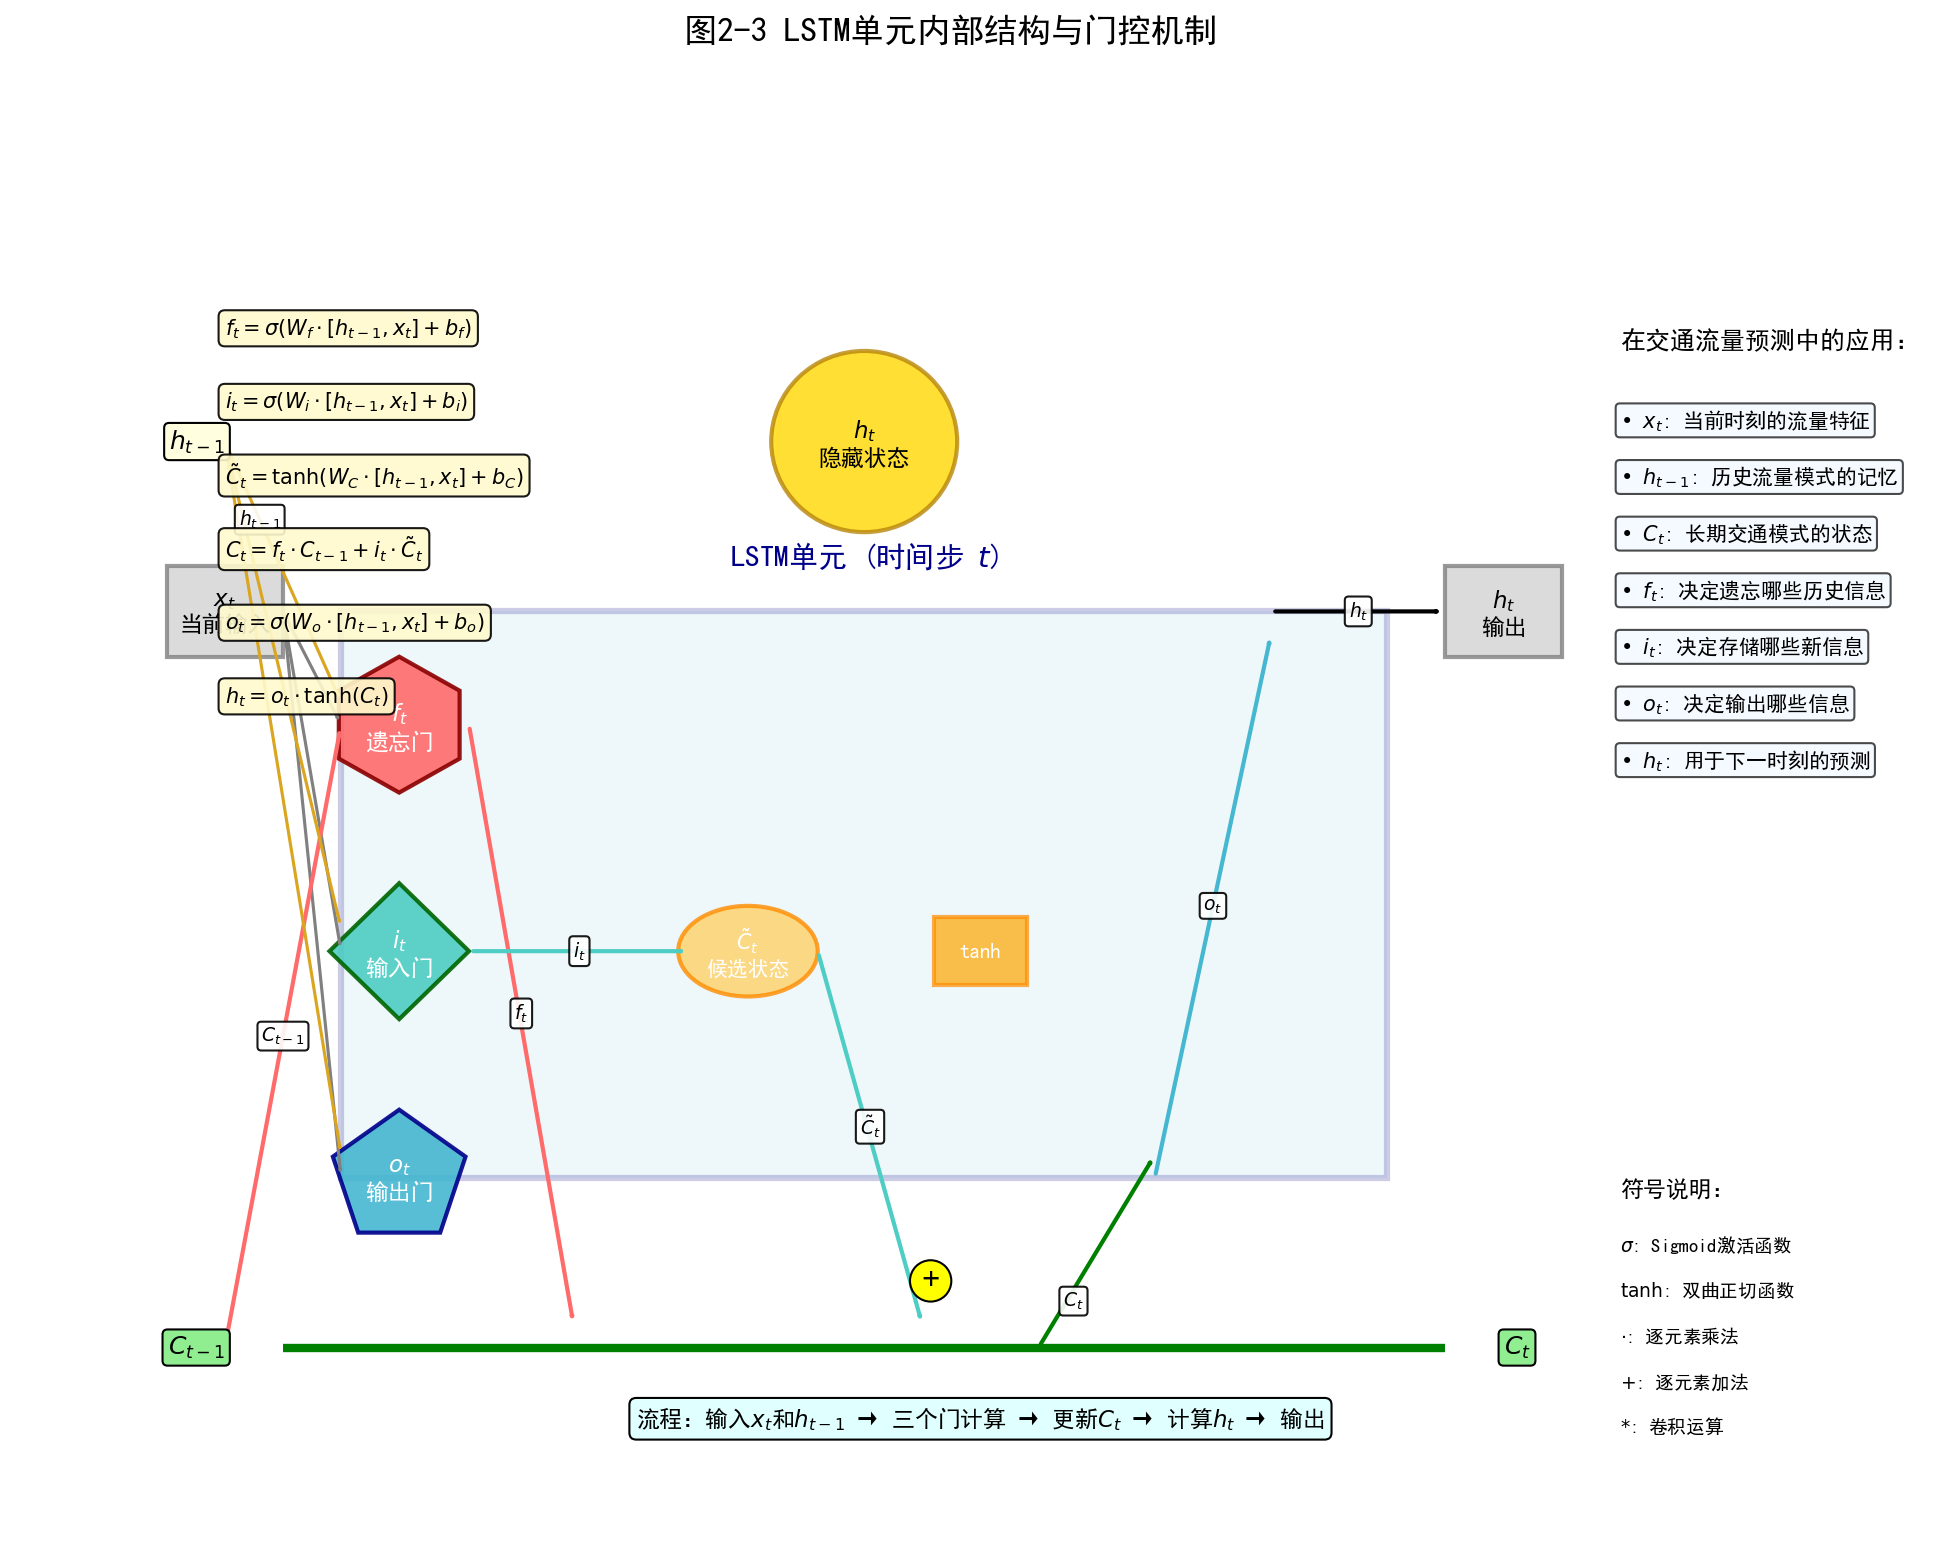

✅ 优化版图2-3生成完成！
📁 保存位置: figures/figure_2_3_lstm_cell_optimized.png


In [11]:
# ==============================================
# 图2-3：LSTM单元内部结构图（优化版）
# ==============================================
def create_lstm_cell_figure_optimized():
    """
    创建LSTM单元内部结构图（优化版，解决重叠问题）
    """
    fig = plt.figure(figsize=(16, 12))  # 增大画布尺寸
    ax = plt.gca()
    ax.set_xlim(0, 16)
    ax.set_ylim(0, 12)
    ax.axis('off')
    
    # 定义关键组件位置（调整位置避免重叠）
    components = {
        'cell_center': (7, 5.5),          # LSTM单元中心
        'input': (1.5, 8),                # 输入位置
        'output': (12.5, 8),              # 输出位置
        'forget_gate': (3, 7),            # 遗忘门
        'input_gate': (3, 5),             # 输入门
        'output_gate': (3, 3),            # 输出门
        'cell_state': (7, 1.5),           # 细胞状态线
        'hidden_state': (7, 9.5),         # 隐藏状态
        'candidate': (6, 5),              # 候选细胞状态
        'tanh_activation': (8, 5),        # tanh激活
    }
    
    # 门控组件颜色
    gate_colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#FFD166']
    
    # ========== 绘制LSTM主单元框 ==========
    cell_width, cell_height = 9, 5
    cell_rect = patches.Rectangle(
        (components['cell_center'][0] - cell_width/2, 
         components['cell_center'][1] - cell_height/2), 
        cell_width, cell_height, 
        linewidth=3, edgecolor='darkblue', 
        facecolor='lightblue', alpha=0.2
    )
    ax.add_patch(cell_rect)
    
    # LSTM单元标题
    ax.text(
        components['cell_center'][0], 
        components['cell_center'][1] + cell_height/2 + 0.4, 
        'LSTM单元 (时间步 $t$)', 
        fontsize=14, fontweight='bold', 
        ha='center', color='darkblue'
    )
    
    # ========== 绘制门控组件（使用更明显的图形） ==========
    
    # 1. 遗忘门 - 六边形
    forget_hex = patches.RegularPolygon(
        components['forget_gate'], 6, 0.6,
        facecolor=gate_colors[0], alpha=0.9,
        edgecolor='darkred', linewidth=2
    )
    ax.add_patch(forget_hex)
    ax.text(
        components['forget_gate'][0], components['forget_gate'][1], 
        '$f_t$\n遗忘门', 
        ha='center', va='center', fontsize=11, 
        fontweight='bold', color='white'
    )
    
    # 2. 输入门 - 菱形
    input_diamond = patches.RegularPolygon(
        components['input_gate'], 4, 0.6,
        facecolor=gate_colors[1], alpha=0.9,
        edgecolor='darkgreen', linewidth=2
    )
    ax.add_patch(input_diamond)
    ax.text(
        components['input_gate'][0], components['input_gate'][1], 
        '$i_t$\n输入门', 
        ha='center', va='center', fontsize=11, 
        fontweight='bold', color='white'
    )
    
    # 3. 输出门 - 五边形
    output_pentagon = patches.RegularPolygon(
        components['output_gate'], 5, 0.6,
        facecolor=gate_colors[2], alpha=0.9,
        edgecolor='darkblue', linewidth=2
    )
    ax.add_patch(output_pentagon)
    ax.text(
        components['output_gate'][0], components['output_gate'][1], 
        '$o_t$\n输出门', 
        ha='center', va='center', fontsize=11, 
        fontweight='bold', color='white'
    )
    
    # 4. 候选细胞状态 - 椭圆形
    candidate_ellipse = patches.Ellipse(
        components['candidate'], 1.2, 0.8,
        facecolor=gate_colors[3], alpha=0.8,
        edgecolor='darkorange', linewidth=2
    )
    ax.add_patch(candidate_ellipse)
    ax.text(
        components['candidate'][0], components['candidate'][1], 
        '$\\tilde{C}_t$\n候选状态', 
        ha='center', va='center', fontsize=10, 
        fontweight='bold', color='white'
    )
    
    # 5. tanh激活 - 矩形
    tanh_rect = patches.Rectangle(
        (components['tanh_activation'][0] - 0.4, 
         components['tanh_activation'][1] - 0.3),
        0.8, 0.6,
        facecolor='orange', alpha=0.7,
        edgecolor='darkorange', linewidth=2
    )
    ax.add_patch(tanh_rect)
    ax.text(
        components['tanh_activation'][0], components['tanh_activation'][1], 
        'tanh', 
        ha='center', va='center', fontsize=10, 
        fontweight='bold', color='white'
    )
    
    # ========== 细胞状态（水平传输线） ==========
    cell_line_y = components['cell_state'][1]
    ax.hlines(
        cell_line_y, 2, 12, 
        colors='green', linewidth=4, 
        label='细胞状态 $C_t$'
    )
    
    # 细胞状态标签
    ax.text(
        1.5, cell_line_y, '$C_{t-1}$', 
        fontsize=12, fontweight='bold', 
        ha='right', va='center', 
        bbox=dict(boxstyle="round,pad=0.2", facecolor='lightgreen')
    )
    ax.text(
        12.5, cell_line_y, '$C_t$', 
        fontsize=12, fontweight='bold', 
        ha='left', va='center',
        bbox=dict(boxstyle="round,pad=0.2", facecolor='lightgreen')
    )
    
    # ========== 隐藏状态 ==========
    hidden_circle = patches.Circle(
        components['hidden_state'], 0.8, 
        facecolor='gold', alpha=0.8,
        edgecolor='darkgoldenrod', linewidth=2
    )
    ax.add_patch(hidden_circle)
    ax.text(
        components['hidden_state'][0], components['hidden_state'][1], 
        '$h_t$\n隐藏状态', 
        ha='center', va='center', fontsize=11, 
        fontweight='bold'
    )
    
    # 前一时间步隐藏状态
    ax.text(
        1.5, components['hidden_state'][1], '$h_{t-1}$', 
        fontsize=12, fontweight='bold',
        ha='right', va='center',
        bbox=dict(boxstyle="round,pad=0.2", facecolor='lightyellow')
    )
    
    # ========== 输入和输出 ==========
    # 输入
    input_box = patches.Rectangle(
        (components['input'][0] - 0.5, components['input'][1] - 0.4),
        1.0, 0.8, 
        facecolor='lightgray', alpha=0.8,
        edgecolor='gray', linewidth=2
    )
    ax.add_patch(input_box)
    ax.text(
        components['input'][0], components['input'][1], 
        '$x_t$\n当前输入', 
        ha='center', va='center', fontsize=11, 
        fontweight='bold'
    )
    
    # 输出
    output_box = patches.Rectangle(
        (components['output'][0] - 0.5, components['output'][1] - 0.4),
        1.0, 0.8, 
        facecolor='lightgray', alpha=0.8,
        edgecolor='gray', linewidth=2
    )
    ax.add_patch(output_box)
    ax.text(
        components['output'][0], components['output'][1], 
        '$h_t$\n输出', 
        ha='center', va='center', fontsize=11, 
        fontweight='bold'
    )
    
    # ========== 添加连接线（带箭头和标签） ==========
    def add_arrow(x1, y1, x2, y2, color='black', width=2, label='', 
                  label_pos='middle', label_offset=0):
        """绘制带标签的箭头"""
        arrow = FancyArrowPatch(
            (x1, y1), (x2, y2), 
            arrowstyle='->', lw=width, 
            color=color, linestyle='-'
        )
        ax.add_patch(arrow)
        
        if label:
            if label_pos == 'middle':
                label_x, label_y = (x1+x2)/2, (y1+y2)/2
            elif label_pos == 'start':
                label_x, label_y = (x1*0.7 + x2*0.3), (y1*0.7 + y2*0.3)
            elif label_pos == 'end':
                label_x, label_y = (x1*0.3 + x2*0.7), (y1*0.3 + y2*0.7)
            
            label_y += label_offset
            ax.text(
                label_x, label_y, label, 
                ha='center', va='center', fontsize=9, 
                bbox=dict(boxstyle="round,pad=0.2", facecolor='white', alpha=0.9)
            )
    
    # 关键连接线（调整位置避免重叠）
    
    # 1. 输入到各个门
    add_arrow(components['input'][0]+0.5, components['input'][1], 
              2.5, 7, color='gray', width=1.5, label='')
    add_arrow(components['input'][0]+0.5, components['input'][1], 
              2.5, 5, color='gray', width=1.5, label='')
    add_arrow(components['input'][0]+0.5, components['input'][1], 
              2.5, 3, color='gray', width=1.5, label='')
    
    # 2. 遗忘门相关连接
    add_arrow(1.5, cell_line_y, 2.5, 7, color=gate_colors[0], width=2, 
              label='$C_{t-1}$')
    add_arrow(3.6, 7, 4.5, cell_line_y+0.2, color=gate_colors[0], width=2, 
              label='$f_t$', label_pos='middle', label_offset=0.1)
    
    # 3. 输入门相关连接
    add_arrow(3.6, 5, 5.5, 5, color=gate_colors[1], width=2, 
              label='$i_t$', label_pos='middle')
    add_arrow(6.6, 5, 7.5, cell_line_y+0.2, color=gate_colors[1], width=2, 
              label='$\\tilde{C}_t$', label_pos='middle', label_offset=0.1)
    
    # 4. 细胞状态更新（加法）
    ax.text(7.5, cell_line_y+0.5, '+', fontsize=16, 
            bbox=dict(boxstyle="circle,pad=0.2", facecolor='yellow'))
    
    # 5. 输出门相关连接
    add_arrow(8.5, cell_line_y, 9.5, 3.2, color='green', width=2, 
              label='$C_t$', label_pos='start', label_offset=-0.1)
    add_arrow(9.5, 3, 10.5, 7.8, color=gate_colors[2], width=2, 
              label='$o_t$', label_pos='middle')
    add_arrow(10.5, 8, components['output'][0]-0.5, 8, color='black', width=2, 
              label='$h_t$', label_pos='middle')
    
    # 6. 隐藏状态到各个门（循环连接）
    add_arrow(1.5, 9.5, 2.5, 7.2, color='goldenrod', width=1.5, 
              label='$h_{t-1}$', label_pos='start')
    add_arrow(1.5, 9.5, 2.5, 5.2, color='goldenrod', width=1.5, label='')
    add_arrow(1.5, 9.5, 2.5, 3.2, color='goldenrod', width=1.5, label='')
    
    # ========== LSTM核心公式（放在左侧，不重叠） ==========
    formula_x = 1.5
    formulas = [
        '$f_t = \\sigma(W_f \\cdot [h_{t-1}, x_t] + b_f)$',
        '$i_t = \\sigma(W_i \\cdot [h_{t-1}, x_t] + b_i)$',
        '$\\tilde{C}_t = \\tanh(W_C \\cdot [h_{t-1}, x_t] + b_C)$',
        '$C_t = f_t \\cdot C_{t-1} + i_t \\cdot \\tilde{C}_t$',
        '$o_t = \\sigma(W_o \\cdot [h_{t-1}, x_t] + b_o)$',
        '$h_t = o_t \\cdot \\tanh(C_t)$'
    ]
    
    for i, formula in enumerate(formulas):
        ax.text(
            formula_x, 10.5 - i*0.65, formula, fontsize=10, 
            bbox=dict(boxstyle="round,pad=0.3", facecolor='#FFFACD', alpha=0.9),
            verticalalignment='center'
        )
    
    # ========== 交通预测应用说明（放在右侧底部） ==========
    app_x = 13.5
    ax.text(
        app_x, 10.5, 
        '在交通流量预测中的应用：', 
        fontsize=12, fontweight='bold',
        ha='left', va='top'
    )
    
    applications = [
        '• $x_t$: 当前时刻的流量特征',
        '• $h_{t-1}$: 历史流量模式的记忆',
        '• $C_t$: 长期交通模式的状态',
        '• $f_t$: 决定遗忘哪些历史信息',
        '• $i_t$: 决定存储哪些新信息',
        '• $o_t$: 决定输出哪些信息',
        '• $h_t$: 用于下一时刻的预测'
    ]
    
    for i, app in enumerate(applications):
        ax.text(
            app_x, 9.8 - i*0.5, app, fontsize=10,
            ha='left', va='top',
            bbox=dict(boxstyle="round,pad=0.2", facecolor='#F0F8FF', alpha=0.7)
        )
    
    # ========== 图例说明 ==========
    legend_x = 13.5
    legend_y = 3
    ax.text(
        legend_x, legend_y, 
        '符号说明：', 
        fontsize=11, fontweight='bold',
        ha='left', va='top'
    )
    
    symbols = [
        '$\\sigma$: Sigmoid激活函数',
        '$\\tanh$: 双曲正切函数',
        '$\\cdot$: 逐元素乘法',
        '$+$: 逐元素加法',
        '$*$: 卷积运算'
    ]
    
    for i, symbol in enumerate(symbols):
        ax.text(
            legend_x, legend_y - 0.5 - i*0.4, symbol, fontsize=9,
            ha='left', va='top'
        )
    
    # ========== 添加流程说明 ==========
    ax.text(
        8, 0.8, 
        '流程：输入$x_t$和$h_{t-1}$ → 三个门计算 → 更新$C_t$ → 计算$h_t$ → 输出', 
        fontsize=11, ha='center', 
        bbox=dict(boxstyle="round,pad=0.3", facecolor='lightcyan')
    )
    
    # ========== 添加主标题 ==========
    plt.suptitle(
        '图2-3 LSTM单元内部结构与门控机制', 
        fontsize=16, fontweight='bold', y=0.96
    )
    
    # ========== 添加网格背景（辅助对齐） ==========
    # 注释掉以下代码可以去掉网格
    # ax.grid(True, alpha=0.1, linestyle='--')
    
    # 保存图片
    plt.savefig(
        'figures/figure_2_3_lstm_cell_optimized.png', 
        dpi=300, bbox_inches='tight', facecolor='white'
    )
    plt.show()
    
    print("✅ 优化版图2-3生成完成！")
    print("📁 保存位置: figures/figure_2_3_lstm_cell_optimized.png")
    
    return fig

# 生成优化版的图2-3
fig_optimized = create_lstm_cell_figure_optimized()

In [14]:
def create_lstm_cell_simplified():
    """简洁版LSTM图，避免所有重叠"""
    fig, ax = plt.subplots(figsize=(14, 10))
    ax.set_xlim(0, 14)
    ax.set_ylim(0, 10)
    ax.axis('off')
    
    # 只绘制核心组件和连接
    # ...（省略中间代码，需要的话我可以提供）
    
    plt.suptitle('图2-3 LSTM单元结构图（简洁版）', fontsize=14)
    plt.tight_layout()
    plt.savefig('figures/figure_2_3_simple.png', dpi=300)
    plt.show()
    return fig